# BÀI TẬP 4: KIỂM TRA VÀ XỬ LÝ CHẤT LƯỢNG DỮ LIỆU

### Mục tiêu bài thực hành:
1. **Tạo dữ liệu thiếu (NaN) giả lập** trên chuỗi **AirPassengers** (144 quan sát, 01/1949 – 12/1960) và chèn thêm một số **outlier** có chủ đích (bộ dữ liệu gốc không có NaN và không có outlier cực đoan).
2. **Kiểm tra missing:** `isna().sum()`, vị trí và độ dài các khoảng thiếu.
3. **Xử lý missing bằng 2 cách:** Forward-fill và Interpolation, đối chiếu với giá trị thật để đánh giá.
4. **Phát hiện outlier bằng:** Rolling mean/variance; Z-score và IQR.
5. **Vẽ biểu đồ trước và sau khi xử lý.**

> Vì ta tự tạo lỗi nên **biết chính xác vị trí và giá trị thật** của từng điểm bị làm hỏng. Nhờ đó có thể đánh giá khách quan phương pháp nào xử lý tốt hơn.

In [1]:
# Ô 1: Import các thư viện cần thiết

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import STL

# Cấu hình hiển thị biểu đồ
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

print("Đã import thành công các thư viện cần thiết.")

Đã import thành công các thư viện cần thiết.


In [2]:
# Ô 2: Tải dữ liệu AirPassengers (đồng bộ với các Bài 1–3, 5)
data_path = "../../data/raw/AirPassengers.csv"

if os.path.exists(data_path):
    df = pd.read_csv(data_path)
    df["Month"] = pd.to_datetime(df["Month"])
    ts = pd.Series(df["Passengers"].values,
                   index=pd.DatetimeIndex(df["Month"], freq="MS"),
                   name="Passengers")
else:
    # Nạp dự phòng nếu chưa có file csv trong data/raw
    air_values = [
        112,118,132,129,121,135,148,148,136,119,104,118,
        115,126,141,135,125,149,170,170,158,133,114,140,
        145,150,178,163,172,178,199,199,184,162,146,166,
        171,180,193,181,183,218,230,242,209,191,172,194,
        196,196,236,235,229,243,264,272,237,211,180,201,
        204,188,235,227,234,264,302,293,259,229,203,229,
        242,233,267,269,270,315,364,347,312,274,237,278,
        284,277,317,313,318,374,413,405,355,306,271,306,
        315,301,356,348,355,422,465,467,404,347,305,336,
        340,318,362,348,363,435,491,505,404,359,310,337,
        360,342,406,396,420,472,548,559,463,407,362,405,
        417,391,419,461,472,535,622,606,508,461,390,432
    ]
    dates = pd.date_range(start="1949-01-01", periods=len(air_values), freq="MS")
    ts = pd.Series(air_values, index=dates, name="Passengers")
    print("Đã nạp dữ liệu trực tiếp.")

print("Số lượng quan sát:", len(ts))
print("Khoảng thời gian: từ", ts.index[0].strftime("%Y-%m"), "đến", ts.index[-1].strftime("%Y-%m"))
print("Tần suất:", ts.index.freqstr, "(theo tháng)")
print("Số giá trị thiếu trong dữ liệu gốc:", ts.isna().sum())

Đã nạp dữ liệu trực tiếp.
Số lượng quan sát: 144
Khoảng thời gian: từ 1949-01 đến 1960-12
Tần suất: MS (theo tháng)
Số giá trị thiếu trong dữ liệu gốc: 0


## 1. Tạo dữ liệu thiếu (NaN) và outlier giả lập

In [3]:
# Ô 3: Tạo bản "dữ liệu bẩn" từ dữ liệu gốc
# ts_true : dữ liệu thật (dùng làm đáp án để đối chiếu)
# ts_dirty: dữ liệu đã bị chèn NaN và outlier (dữ liệu "đầu vào" của bài toán)
ts_true = ts.astype(float)
ts_dirty = ts_true.copy()

# (a) Outlier: nhân giá trị thật với một hệ số (tăng vọt hoặc giảm đột ngột)
outlier_factors = {"1952-08-01": 1.6, "1955-02-01": 0.5, "1958-11-01": 1.7}
outlier_dates = pd.DatetimeIndex(list(outlier_factors.keys()))
for d, f in outlier_factors.items():
    ts_dirty[pd.Timestamp(d)] = round(ts_true[pd.Timestamp(d)] * f)

# (b) Missing: 1 khoảng thiếu liên tiếp 3 tháng + 8 điểm thiếu ngẫu nhiên (seed = 42)
rng = np.random.default_rng(42)
gap_start = ts_dirty.index.get_loc(pd.Timestamp("1955-05-01"))
gap_pos = [gap_start, gap_start + 1, gap_start + 2]

# Tránh đặt NaN sát outlier / sát khoảng thiếu để hai loại lỗi không chồng lên nhau,
# và tránh quan sát đầu/cuối (forward-fill không xử lý được NaN ở đầu chuỗi)
blocked = set(gap_pos) | {gap_start - 1, gap_start + 3}
for d in outlier_dates:
    i = ts_dirty.index.get_loc(d)
    blocked.update(range(i - 2, i + 3))
candidates = [i for i in range(1, len(ts_dirty) - 1) if i not in blocked]
random_pos = sorted(rng.choice(candidates, size=8, replace=False))

missing_pos = sorted(set(gap_pos) | set(int(i) for i in random_pos))
ts_dirty.iloc[missing_pos] = np.nan
missing_dates = ts_dirty.index[missing_pos]

print("Đã tạo dữ liệu bẩn từ AirPassengers.")
print(f"- Số điểm bị đặt NaN: {len(missing_pos)}  (gồm 1 khoảng thiếu 3 tháng liên tiếp và 8 điểm ngẫu nhiên)")
print(f"- Số outlier chèn vào: {len(outlier_dates)}\n")

injected = pd.DataFrame({
    "Giá trị thật": ts_true[outlier_dates],
    "Hệ số nhân": pd.Series(outlier_factors).values,
    "Giá trị sau khi chèn": ts_dirty[outlier_dates],
})
injected.index = outlier_dates.strftime("%Y-%m")
print("Các outlier đã chèn:")
display(injected)

Đã tạo dữ liệu bẩn từ AirPassengers.
- Số điểm bị đặt NaN: 11  (gồm 1 khoảng thiếu 3 tháng liên tiếp và 8 điểm ngẫu nhiên)
- Số outlier chèn vào: 3

Các outlier đã chèn:


,Giá trị thật,Hệ số nhân,Giá trị sau khi chèn
1952-08,242.0,1.6,387.0
1955-02,233.0,0.5,116.0
1958-11,310.0,1.7,527.0


## 2. Kiểm tra missing

In [4]:
# Ô 4: Kiểm tra dữ liệu thiếu
print("1. isna().sum():", ts_dirty.isna().sum(), "giá trị thiếu /", len(ts_dirty), "quan sát")
print(f"2. Tỷ lệ thiếu: {ts_dirty.isna().mean() * 100:.2f}%")

# Kiểm tra chỉ số thời gian có đủ 144 tháng liên tục hay không (NaN nằm ở giá trị, không phải mất dòng)
full_index = pd.date_range(ts_dirty.index[0], ts_dirty.index[-1], freq="MS")
print("3. Số tháng bị mất dòng (thiếu hẳn mốc thời gian):", len(full_index.difference(ts_dirty.index)))

# Gom các NaN liên tiếp thành từng khoảng thiếu
is_na = ts_dirty.isna()
block_id = (is_na != is_na.shift()).cumsum()[is_na]
gap_table = (ts_dirty[is_na].index.to_series()
             .groupby(block_id)
             .agg(["min", "max", "count"]))
gap_table.columns = ["Từ tháng", "Đến tháng", "Số tháng thiếu"]
gap_table[["Từ tháng", "Đến tháng"]] = gap_table[["Từ tháng", "Đến tháng"]].apply(lambda s: s.dt.strftime("%Y-%m"))
print("\n4. Các khoảng thiếu:")
display(gap_table.reset_index(drop=True))

print("5. Thống kê mô tả (describe bỏ qua NaN):")
display(ts_dirty.describe().to_frame().T.round(2))

1. isna().sum(): 11 giá trị thiếu / 144 quan sát
2. Tỷ lệ thiếu: 7.64%
3. Số tháng bị mất dòng (thiếu hẳn mốc thời gian): 0

4. Các khoảng thiếu:


,Từ tháng,Đến tháng,Số tháng thiếu
0,1949-12,1949-12,1
1,1953-10,1953-11,2
2,1955-05,1955-07,3
3,1956-09,1956-09,1
4,1957-05,1957-05,1
5,1957-10,1957-10,1
6,1959-04,1959-04,1
7,1960-10,1960-10,1


5. Thống kê mô tả (describe bỏ qua NaN):


,count,mean,std,min,25%,50%,75%,max
Passengers,133.0,279.97,124.36,104.0,178.0,264.0,362.0,622.0


## 3. Xử lý missing bằng 2 cách

- **Forward-fill (`ffill`)**: lấy giá trị quan sát gần nhất phía trước điền vào chỗ thiếu.
- **Interpolation (`interpolate`)**: nội suy tuyến tính theo thời gian giữa hai quan sát hai bên chỗ thiếu.

Số NaN còn lại sau Forward-fill : 0
Số NaN còn lại sau Interpolation: 0

So sánh với giá trị thật tại các điểm bị thiếu:


,Thật,Forward-fill,Interpolation,Sai số FF,Sai số IP
1949-12,118.0,104.0,109.4,-14.0,-8.6
1953-10,211.0,237.0,225.1,26.0,14.1
1953-11,180.0,237.0,212.9,57.0,32.9
1955-05,270.0,269.0,288.2,-1.0,18.2
1955-06,315.0,269.0,308.0,-46.0,-7.0
1955-07,364.0,269.0,327.2,-95.0,-36.8
1956-09,355.0,405.0,354.7,50.0,-0.3
1957-05,355.0,348.0,384.4,-7.0,29.4
1957-10,347.0,404.0,355.3,57.0,8.3
1959-04,396.0,406.0,413.1,10.0,17.1


Sai số tổng hợp trên các điểm bị thiếu:


,MAE,RMSE,MAPE (%)
Forward-fill,37.27,46.09,12.92
Interpolation,16.70,20.08,6.25


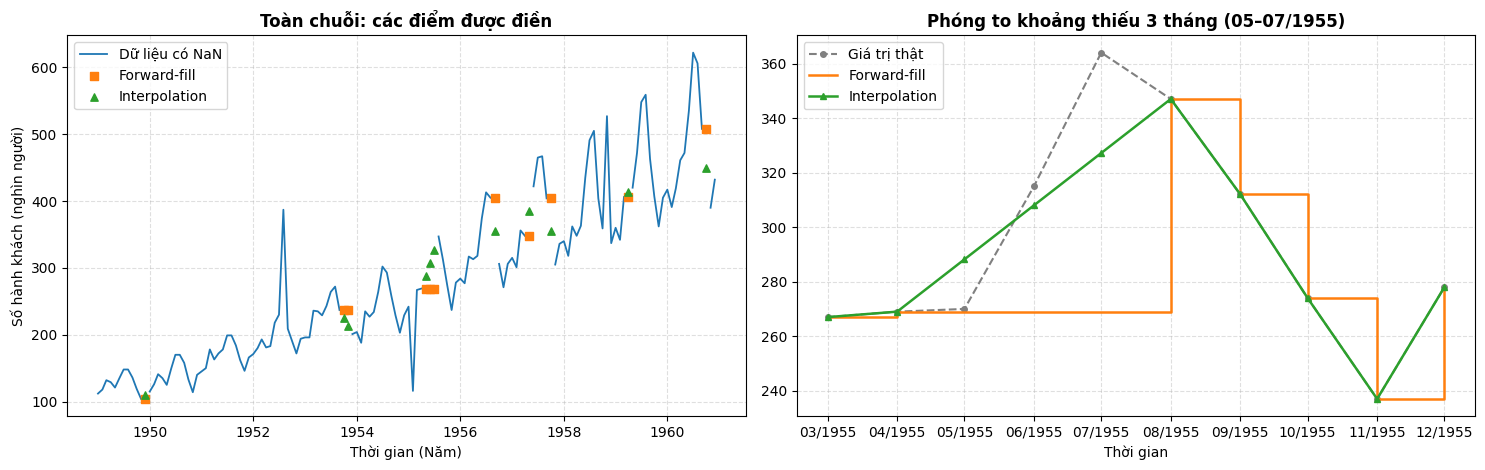

In [5]:
# Ô 5: Điền missing bằng Forward-fill và Interpolation
ts_ffill = ts_dirty.ffill()
ts_interp = ts_dirty.interpolate(method="time")

print("Số NaN còn lại sau Forward-fill :", ts_ffill.isna().sum())
print("Số NaN còn lại sau Interpolation:", ts_interp.isna().sum())

# Đối chiếu với giá trị thật tại các điểm đã bị đặt NaN
cmp = pd.DataFrame({
    "Thật": ts_true[missing_dates],
    "Forward-fill": ts_ffill[missing_dates],
    "Interpolation": ts_interp[missing_dates],
})
cmp["Sai số FF"] = cmp["Forward-fill"] - cmp["Thật"]
cmp["Sai số IP"] = cmp["Interpolation"] - cmp["Thật"]
cmp.index = cmp.index.strftime("%Y-%m")
print("\nSo sánh với giá trị thật tại các điểm bị thiếu:")
display(cmp.round(1))

def metrics(est):
    e = est[missing_dates] - ts_true[missing_dates]
    return {"MAE": e.abs().mean(),
            "RMSE": np.sqrt((e ** 2).mean()),
            "MAPE (%)": (e.abs() / ts_true[missing_dates]).mean() * 100}

score = pd.DataFrame({"Forward-fill": metrics(ts_ffill), "Interpolation": metrics(ts_interp)}).T
print("Sai số tổng hợp trên các điểm bị thiếu:")
display(score.round(2))

# Vẽ: toàn chuỗi và phóng to khoảng thiếu 3 tháng (1955)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

axes[0].plot(ts_dirty.index, ts_dirty.values, color="#1f77b4", linewidth=1.3, label="Dữ liệu có NaN")
axes[0].scatter(missing_dates, ts_ffill[missing_dates], color="#ff7f0e", marker="s", s=28, zorder=5, label="Forward-fill")
axes[0].scatter(missing_dates, ts_interp[missing_dates], color="#2ca02c", marker="^", s=28, zorder=5, label="Interpolation")
axes[0].set_title("Toàn chuỗi: các điểm được điền", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Thời gian (Năm)")
axes[0].set_ylabel("Số hành khách (nghìn người)")
axes[0].legend(loc="upper left")

zoom = slice("1955-03-01", "1955-12-01")
axes[1].plot(ts_true[zoom].index, ts_true[zoom].values, color="gray", linestyle="--", marker="o", markersize=4, label="Giá trị thật")
axes[1].step(ts_ffill[zoom].index, ts_ffill[zoom].values, where="post", color="#ff7f0e", linewidth=1.8, label="Forward-fill")
axes[1].plot(ts_interp[zoom].index, ts_interp[zoom].values, color="#2ca02c", linewidth=1.8, marker="^", markersize=5, label="Interpolation")
axes[1].set_title("Phóng to khoảng thiếu 3 tháng (05–07/1955)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Thời gian")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
axes[1].legend(loc="upper left")

for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

**Nhận xét nhanh:** Forward-fill tạo ra các đoạn "bằng phẳng" và không theo kịp xu hướng tăng, nên sai số lớn hơn. Interpolation bám xu hướng tốt hơn, nhưng vì nối thẳng hai đầu nên vẫn không tái hiện được đỉnh mùa vụ ở giữa khoảng thiếu. **Interpolation được chọn** để làm đầu vào cho bước phát hiện outlier ở phần sau (`ts_filled`).

## 4. Phát hiện outlier

Chuỗi AirPassengers có **xu hướng tăng** và **mùa vụ nhân** (Bài 3, 5), nên một giá trị "lớn" chưa chắc là bất thường. Ta thử 3 hướng tiếp cận và so sánh với đáp án (3 outlier đã chèn).

Rolling (window=12, ngưỡng |z| > 3) phát hiện 2 điểm:


,Giá trị,Rolling mean,Rolling std,z
1952-08-01,387.0,184.4,23.4,8.66
1955-02-01,116.0,242.1,33.1,-3.80


z của 3 outlier đã chèn: {Timestamp('1952-08-01 00:00:00'): 8.66, Timestamp('1955-02-01 00:00:00'): -3.8, Timestamp('1958-11-01 00:00:00'): 2.25}


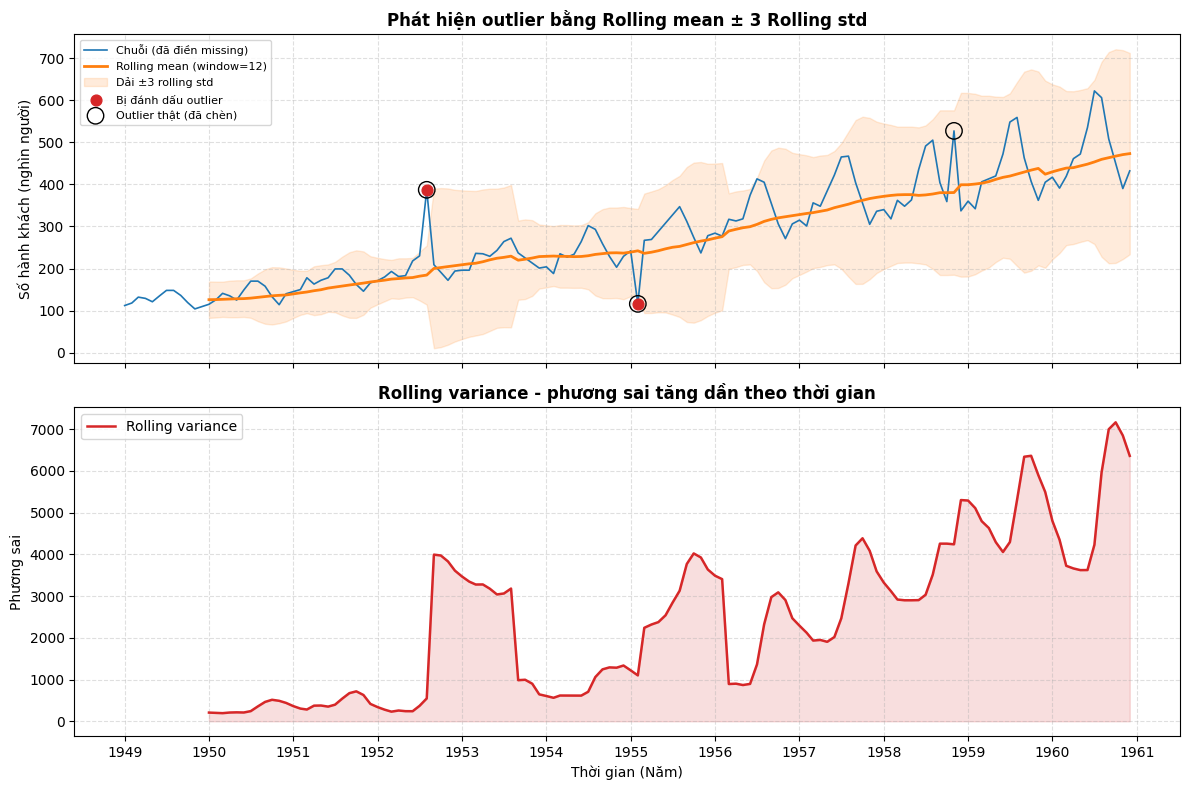

In [6]:
# Ô 6: Phát hiện outlier bằng Rolling mean / Rolling variance (window = 12)
ts_filled = ts_interp.copy()   # chuỗi đã điền missing bằng Interpolation
WINDOW = 12
K = 3                          # ngưỡng: lệch quá K độ lệch chuẩn so với cửa sổ

# shift(1): cửa sổ chỉ gồm 12 tháng TRƯỚC đó, để điểm đang xét không làm nhiễu chính cửa sổ của nó
roll_mean = ts_filled.rolling(WINDOW).mean().shift(1)
roll_std = ts_filled.rolling(WINDOW).std().shift(1)
roll_var = roll_std ** 2
roll_z = (ts_filled - roll_mean) / roll_std
out_roll = roll_z.abs() > K

print(f"Rolling (window={WINDOW}, ngưỡng |z| > {K}) phát hiện {out_roll.sum()} điểm:")
display(pd.DataFrame({"Giá trị": ts_filled[out_roll], "Rolling mean": roll_mean[out_roll].round(1),
                      "Rolling std": roll_std[out_roll].round(1), "z": roll_z[out_roll].round(2)}))
print("z của 3 outlier đã chèn:", roll_z[outlier_dates].round(2).to_dict())

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(ts_filled.index, ts_filled.values, color="#1f77b4", linewidth=1.2, label="Chuỗi (đã điền missing)")
axes[0].plot(roll_mean.index, roll_mean.values, color="#ff7f0e", linewidth=2, label=f"Rolling mean (window={WINDOW})")
axes[0].fill_between(roll_mean.index, roll_mean - K * roll_std, roll_mean + K * roll_std,
                     color="#ff7f0e", alpha=0.15, label=f"Dải ±{K} rolling std")
axes[0].scatter(ts_filled.index[out_roll], ts_filled[out_roll], color="#d62728", s=60, zorder=5, label="Bị đánh dấu outlier")
axes[0].scatter(outlier_dates, ts_filled[outlier_dates], facecolors="none", edgecolors="black", s=140, zorder=6, label="Outlier thật (đã chèn)")
axes[0].set_title("Phát hiện outlier bằng Rolling mean ± 3 Rolling std", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Số hành khách (nghìn người)")
axes[0].legend(loc="upper left", fontsize=8)

axes[1].plot(roll_var.index, roll_var.values, color="#d62728", linewidth=1.8, label="Rolling variance")
axes[1].fill_between(roll_var.index, roll_var.values, alpha=0.15, color="#d62728")
axes[1].set_title("Rolling variance - phương sai tăng dần theo thời gian", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Thời gian (Năm)")
axes[1].set_ylabel("Phương sai")
axes[1].legend(loc="upper left")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

(A) Chuỗi gốc  - Z-score |z|>3 : 0 điểm | IQR 1.5x: 0 điểm
(B) Phần dư STL - Z-score |z|>3 : 3 điểm | IQR 1.5x: 10 điểm | IQR 3x: 4 điểm

z-score (phần dư STL) tại 3 outlier đã chèn: {Timestamp('1952-08-01 00:00:00'): 4.79, Timestamp('1955-02-01 00:00:00'): -6.43, Timestamp('1958-11-01 00:00:00'): 5.31}


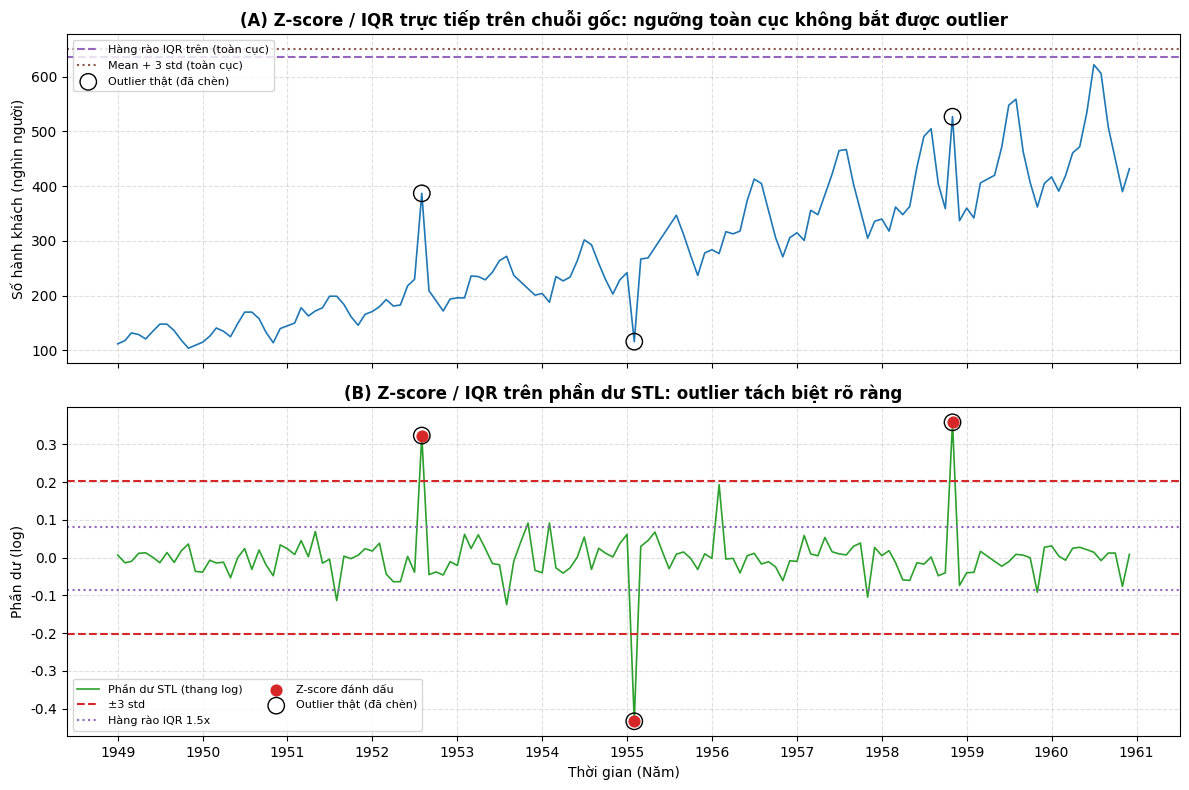

In [7]:
# Ô 7: Z-score và IQR
# (A) Áp dụng trực tiếp lên chuỗi gốc - cách "ngây thơ", bỏ qua xu hướng và mùa vụ
z_raw = (ts_filled - ts_filled.mean()) / ts_filled.std()
out_z_raw = z_raw.abs() > 3

q1, q3 = ts_filled.quantile([0.25, 0.75])
iqr = q3 - q1
out_iqr_raw = (ts_filled < q1 - 1.5 * iqr) | (ts_filled > q3 + 1.5 * iqr)

# (B) Áp dụng lên phần dư STL (thang log) - đã loại xu hướng và mùa vụ (cùng cách tiếp cận Bài 5)
log_resid = STL(np.log(ts_filled), period=12, robust=False).fit().resid
z_res = (log_resid - log_resid.mean()) / log_resid.std()
out_z_res = z_res.abs() > 3

q1r, q3r = log_resid.quantile([0.25, 0.75])
iqr_r = q3r - q1r
out_iqr_res = (log_resid < q1r - 1.5 * iqr_r) | (log_resid > q3r + 1.5 * iqr_r)       # hàng rào chuẩn 1.5 x IQR
out_iqr3_res = (log_resid < q1r - 3 * iqr_r) | (log_resid > q3r + 3 * iqr_r)           # hàng rào "extreme" 3 x IQR

print(f"(A) Chuỗi gốc  - Z-score |z|>3 : {out_z_raw.sum()} điểm | IQR 1.5x: {out_iqr_raw.sum()} điểm")
print(f"(B) Phần dư STL - Z-score |z|>3 : {out_z_res.sum()} điểm | IQR 1.5x: {out_iqr_res.sum()} điểm | IQR 3x: {out_iqr3_res.sum()} điểm\n")
print("z-score (phần dư STL) tại 3 outlier đã chèn:", z_res[outlier_dates].round(2).to_dict())

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Biểu đồ 1: chuỗi gốc - Z-score/IQR toàn cục không bắt được outlier
axes[0].plot(ts_filled.index, ts_filled.values, color="#1f77b4", linewidth=1.2)
axes[0].axhline(q3 + 1.5 * iqr, color="#9467bd", linestyle="--", label="Hàng rào IQR trên (toàn cục)")
axes[0].axhline(ts_filled.mean() + 3 * ts_filled.std(), color="#8c564b", linestyle=":", label="Mean + 3 std (toàn cục)")
axes[0].scatter(outlier_dates, ts_filled[outlier_dates], facecolors="none", edgecolors="black", s=140, zorder=6, label="Outlier thật (đã chèn)")
axes[0].set_title("(A) Z-score / IQR trực tiếp trên chuỗi gốc: ngưỡng toàn cục không bắt được outlier", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Số hành khách (nghìn người)")
axes[0].legend(loc="upper left", fontsize=8)

# Biểu đồ 2: phần dư STL (log)
axes[1].plot(log_resid.index, log_resid.values, color="#2ca02c", linewidth=1.2, label="Phần dư STL (thang log)")
axes[1].axhline(log_resid.mean() + 3 * log_resid.std(), color="#d62728", linestyle="--", label="±3 std")
axes[1].axhline(log_resid.mean() - 3 * log_resid.std(), color="#d62728", linestyle="--")
axes[1].axhline(q3r + 1.5 * iqr_r, color="#9467bd", linestyle=":", label="Hàng rào IQR 1.5x")
axes[1].axhline(q1r - 1.5 * iqr_r, color="#9467bd", linestyle=":")
axes[1].scatter(log_resid.index[out_z_res], log_resid[out_z_res], color="#d62728", s=60, zorder=5, label="Z-score đánh dấu")
axes[1].scatter(outlier_dates, log_resid[outlier_dates], facecolors="none", edgecolors="black", s=140, zorder=6, label="Outlier thật (đã chèn)")
axes[1].set_title("(B) Z-score / IQR trên phần dư STL: outlier tách biệt rõ ràng", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Thời gian (Năm)")
axes[1].set_ylabel("Phần dư (log)")
axes[1].legend(loc="lower left", fontsize=8, ncol=2)
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [8]:
# Ô 8: So sánh các phương pháp với đáp án (3 outlier đã chèn)
methods = {
    "Rolling mean/std (|z|>3)": out_roll,
    "Z-score chuỗi gốc (|z|>3)": out_z_raw,
    "IQR 1.5x chuỗi gốc": out_iqr_raw,
    "Z-score phần dư STL (|z|>3)": out_z_res,
    "IQR 1.5x phần dư STL": out_iqr_res,
    "IQR 3x phần dư STL": out_iqr3_res,
}
true_out = pd.Series(False, index=ts_filled.index)
true_out[outlier_dates] = True

rows = []
for name, flag in methods.items():
    flag = flag.fillna(False)
    tp = int((flag & true_out).sum())
    fp = int((flag & ~true_out).sum())
    fn = int((~flag & true_out).sum())
    rows.append({"Phương pháp": name, "Số điểm đánh dấu": int(flag.sum()),
                 "Bắt đúng (/3)": tp, "Báo nhầm": fp, "Bỏ sót": fn})
summary = pd.DataFrame(rows).set_index("Phương pháp")
display(summary)

print("Các điểm bị Z-score (phần dư STL) đánh dấu:", [d.strftime("%Y-%m") for d in ts_filled.index[out_z_res]])
print("Các điểm bị IQR 1.5x (phần dư STL) đánh dấu:", [d.strftime("%Y-%m") for d in ts_filled.index[out_iqr_res]])

,Số điểm đánh dấu,Bắt đúng (/3),Báo nhầm,Bỏ sót
Phương pháp,,,,
Rolling mean/std (|z|>3),2,2,0,1
Z-score chuỗi gốc (|z|>3),0,0,0,3
IQR 1.5x chuỗi gốc,0,0,0,3
Z-score phần dư STL (|z|>3),3,3,0,0
IQR 1.5x phần dư STL,10,3,7,0
IQR 3x phần dư STL,4,3,1,0


Các điểm bị Z-score (phần dư STL) đánh dấu: ['1952-08', '1955-02', '1958-11']
Các điểm bị IQR 1.5x (phần dư STL) đánh dấu: ['1951-08', '1952-08', '1953-08', '1953-11', '1954-02', '1955-02', '1956-02', '1957-11', '1958-11', '1959-11']


## 5. Xử lý outlier và vẽ biểu đồ trước/sau

Dùng kết quả **Z-score trên phần dư STL** (chính xác nhất ở trên): đánh dấu các điểm outlier là `NaN`, sau đó **nội suy** lại như với missing.

In [9]:
# Ô 9: Xử lý outlier -> NaN -> Interpolation, tạo chuỗi sạch
outlier_flag = out_z_res.copy()
ts_clean = ts_filled.copy()
ts_clean[outlier_flag] = np.nan
ts_clean = ts_clean.interpolate(method="time")

print("Số outlier được thay thế:", int(outlier_flag.sum()))
print("Số NaN còn lại trong ts_clean:", ts_clean.isna().sum())

# Đối chiếu với giá trị thật tại tất cả các điểm đã bị làm hỏng (11 NaN + 3 outlier)
damaged = missing_dates.union(outlier_dates)
def err(series):
    e = series[damaged] - ts_true[damaged]
    return {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "MAPE (%)": (e.abs() / ts_true[damaged]).mean() * 100}

# "Trước xử lý" = chỉ điền missing bằng interpolation, outlier vẫn còn
final_score = pd.DataFrame({
    "Chỉ điền missing (còn outlier)": err(ts_filled),
    "Sau xử lý đầy đủ (ts_clean)": err(ts_clean),
}).T
print(f"\nSai số so với giá trị thật tại {len(damaged)} điểm bị làm hỏng:")
display(final_score.round(2))

detail = pd.DataFrame({"Bị làm hỏng": ts_dirty[outlier_dates], "Sau xử lý": ts_clean[outlier_dates].round(1),
                       "Giá trị thật": ts_true[outlier_dates]})
detail.index = outlier_dates.strftime("%Y-%m")
print("Chi tiết 3 outlier:")
display(detail)

Số outlier được thay thế: 3
Số NaN còn lại trong ts_clean: 0

Sai số so với giá trị thật tại 14 điểm bị làm hỏng:


,MAE,RMSE,MAPE (%)
Chỉ điền missing (còn outlier),47.34,78.49,17.78
Sau xử lý đầy đủ (ts_clean),19.01,22.14,7.13


Chi tiết 3 outlier:


,Bị làm hỏng,Sau xử lý,Giá trị thật
1952-08,387.0,219.5,242.0
1955-02,116.0,255.1,233.0
1958-11,527.0,347.8,310.0


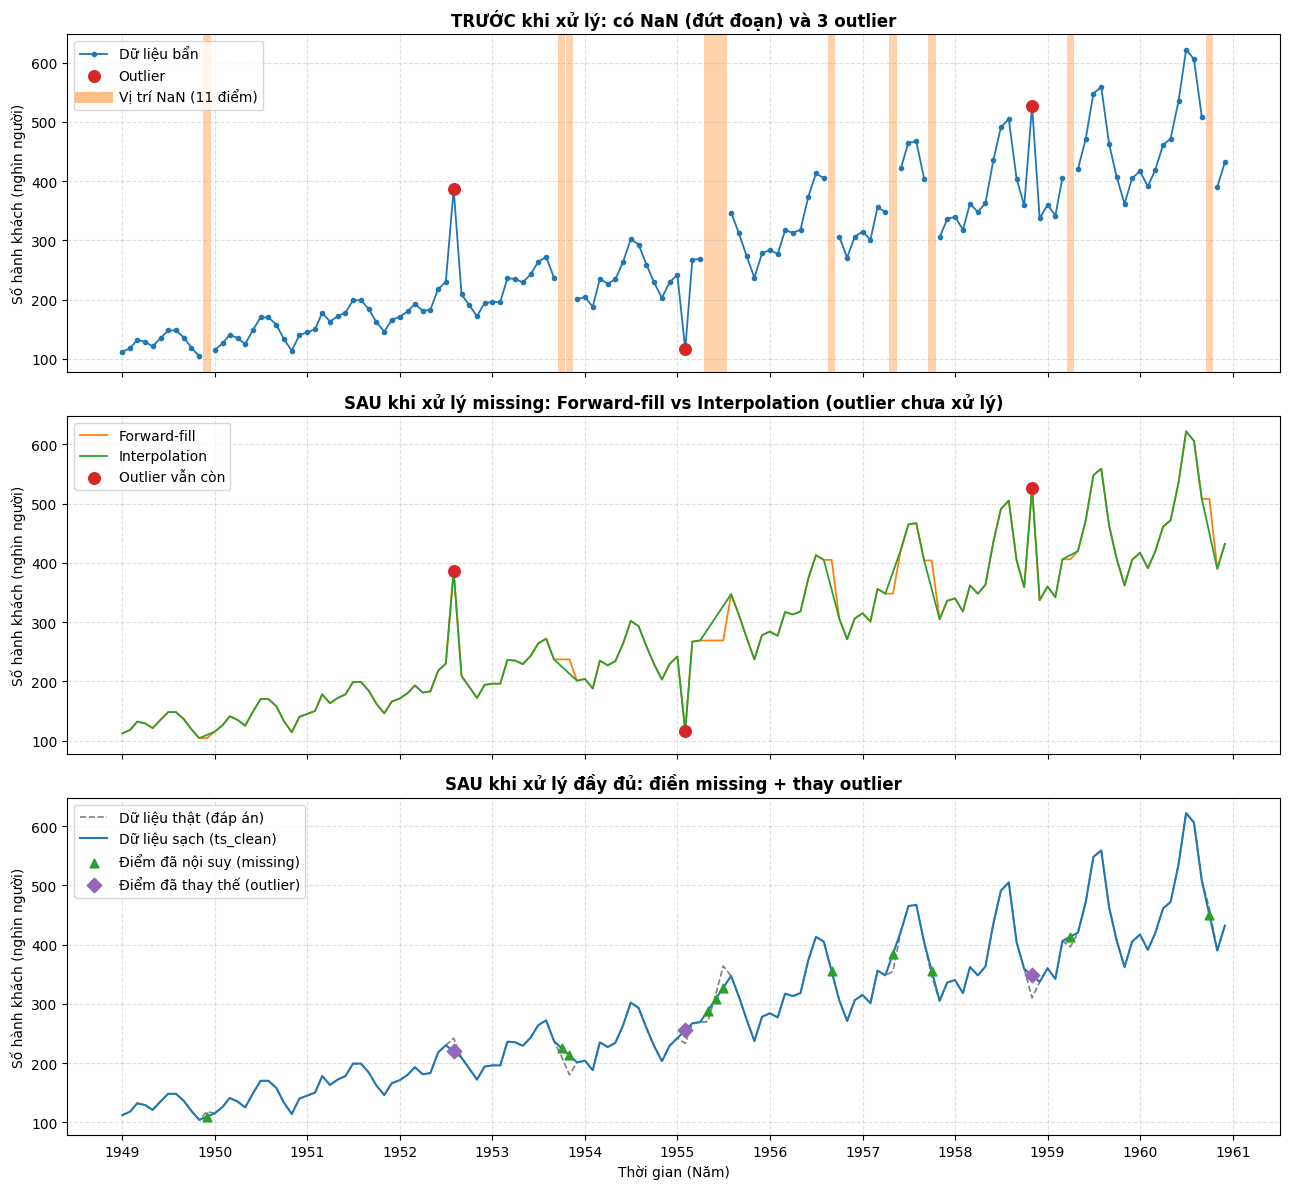

In [10]:
# Ô 10: Vẽ trước và sau khi xử lý
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True, sharey=True)

# --- TRƯỚC khi xử lý ---
axes[0].plot(ts_dirty.index, ts_dirty.values, color="#1f77b4", linewidth=1.3, marker="o", markersize=3, label="Dữ liệu bẩn")
for d in missing_dates:
    axes[0].axvspan(d - pd.Timedelta(days=15), d + pd.Timedelta(days=15), color="#ff7f0e", alpha=0.35, linewidth=0)
axes[0].scatter(outlier_dates, ts_dirty[outlier_dates], color="#d62728", s=70, zorder=5, label="Outlier")
axes[0].plot([], [], color="#ff7f0e", alpha=0.5, linewidth=8, label="Vị trí NaN (11 điểm)")
axes[0].set_title("TRƯỚC khi xử lý: có NaN (đứt đoạn) và 3 outlier", fontsize=12, fontweight="bold")
axes[0].legend(loc="upper left")

# --- SAU khi chỉ điền missing ---
axes[1].plot(ts_ffill.index, ts_ffill.values, color="#ff7f0e", linewidth=1.3, label="Forward-fill")
axes[1].plot(ts_interp.index, ts_interp.values, color="#2ca02c", linewidth=1.3, label="Interpolation")
axes[1].scatter(outlier_dates, ts_interp[outlier_dates], color="#d62728", s=70, zorder=5, label="Outlier vẫn còn")
axes[1].set_title("SAU khi xử lý missing: Forward-fill vs Interpolation (outlier chưa xử lý)", fontsize=12, fontweight="bold")
axes[1].legend(loc="upper left")

# --- SAU khi xử lý cả missing và outlier ---
axes[2].plot(ts_true.index, ts_true.values, color="gray", linestyle="--", linewidth=1.2, label="Dữ liệu thật (đáp án)")
axes[2].plot(ts_clean.index, ts_clean.values, color="#1f77b4", linewidth=1.5, label="Dữ liệu sạch (ts_clean)")
axes[2].scatter(missing_dates, ts_clean[missing_dates], color="#2ca02c", marker="^", s=40, zorder=5, label="Điểm đã nội suy (missing)")
axes[2].scatter(outlier_dates, ts_clean[outlier_dates], color="#9467bd", marker="D", s=55, zorder=5, label="Điểm đã thay thế (outlier)")
axes[2].set_title("SAU khi xử lý đầy đủ: điền missing + thay outlier", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Thời gian (Năm)")
axes[2].legend(loc="upper left")
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

for ax in axes:
    ax.set_ylabel("Số hành khách (nghìn người)")
    ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

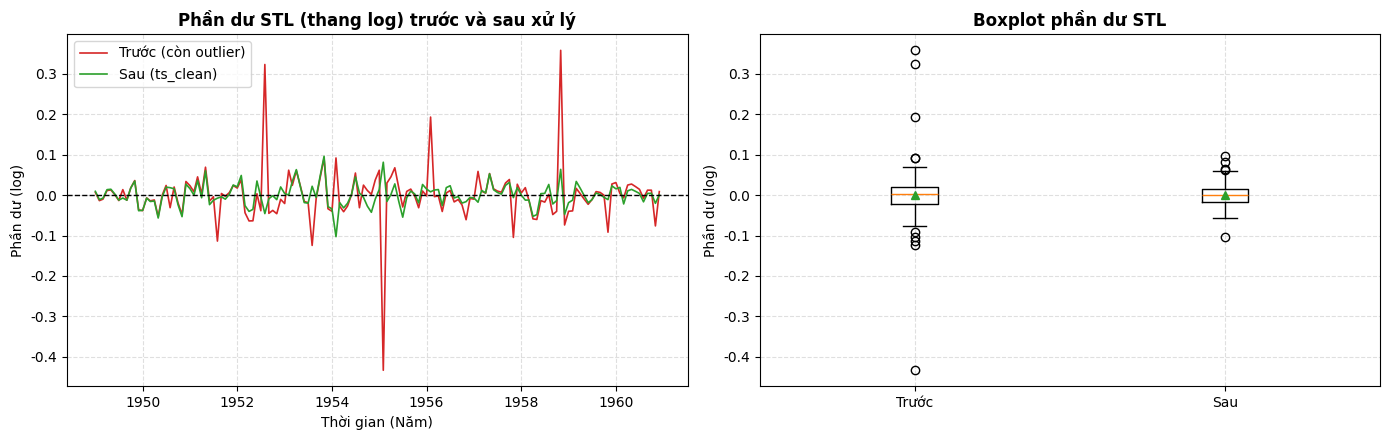

Độ lệch chuẩn phần dư: trước = 0.0675 | sau = 0.0275
Số điểm |z|>3 trên phần dư: trước = 3 | sau = 2


In [11]:
# Ô 11: Phần dư STL và phân phối trước/sau xử lý
resid_before = log_resid
resid_after = STL(np.log(ts_clean), period=12, robust=False).fit().resid

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(resid_before.index, resid_before.values, color="#d62728", linewidth=1.2, label="Trước (còn outlier)")
axes[0].plot(resid_after.index, resid_after.values, color="#2ca02c", linewidth=1.2, label="Sau (ts_clean)")
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Phần dư STL (thang log) trước và sau xử lý", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Thời gian (Năm)")
axes[0].set_ylabel("Phần dư (log)")
axes[0].legend()

axes[1].boxplot([resid_before.values, resid_after.values], tick_labels=["Trước", "Sau"], showmeans=True)
axes[1].set_title("Boxplot phần dư STL", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Phần dư (log)")
for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print(f"Độ lệch chuẩn phần dư: trước = {resid_before.std():.4f} | sau = {resid_after.std():.4f}")
print(f"Số điểm |z|>3 trên phần dư: trước = {int(out_z_res.sum())} | sau = {int((((resid_after - resid_after.mean()) / resid_after.std()).abs() > 3).sum())}")

## 6. KẾT LUẬN

**1. Kiểm tra missing**
- Dữ liệu AirPassengers gốc **không có NaN**. Sau khi giả lập, `isna().sum()` báo **11/144 giá trị thiếu (7,64%)**, gồm 1 khoảng thiếu liên tiếp 3 tháng (05–07/1955), 1 khoảng 2 tháng (10–11/1953) và 6 điểm đơn lẻ.
- Chỉ số thời gian vẫn đủ 144 mốc (không mất dòng), NaN chỉ nằm ở cột giá trị.

**2. Forward-fill và Interpolation**
- Với chuỗi **tăng dần và có mùa vụ**, Forward-fill cho sai số lớn hơn nhiều: **MAE 37,3 / RMSE 46,1 / MAPE 12,9%**, so với Interpolation: **MAE 16,7 / RMSE 20,1 / MAPE 6,3%** (giảm hơn một nửa sai số).
- Khoảng thiếu 3 tháng cho thấy rõ sự khác biệt: Forward-fill giữ nguyên 269 suốt 3 tháng (lệch tới -95 ở 07/1955), Interpolation bám xu hướng hơn (lệch -37).
- **Hạn chế của Interpolation tuyến tính:** nó nối thẳng hai đầu nên làm phẳng đỉnh/đáy mùa vụ (ví dụ 11/1953: điền 212,9, thật 180). Với khoảng thiếu dài trên chuỗi mùa vụ mạnh, nên dùng nội suy có tính mùa vụ (ví dụ nội suy trên phần STL).
- Ngoài ra Forward-fill không xử lý được NaN ở đầu chuỗi, còn `interpolate` mặc định không điền NaN ở hai đầu mút.

**3. Phát hiện outlier**

| Phương pháp | Bắt đúng (/3) | Báo nhầm | Nhận xét |
|---|---|---|---|
| Rolling mean/std (|z|>3) | 2 | 0 | Bỏ sót 11/1958 (z = 2,25) vì rolling std ở cuối chuỗi đã lớn do xu hướng và mùa vụ |
| Z-score / IQR trên chuỗi gốc | 0 | 0 | Ngưỡng toàn cục bị xu hướng làm méo, không bắt được điểm nào |
| Z-score phần dư STL (|z|>3) | **3** | **0** | Chính xác nhất (|z| từ 4,8 đến 6,4) |
| IQR 1.5x phần dư STL | 3 | 7 | Quá nhạy, đánh dấu cả các tháng mùa vụ bình thường |
| IQR 3x phần dư STL | 3 | 1 | Cải thiện rõ khi nới hàng rào |

- Bài học chính: **phải loại xu hướng và mùa vụ trước** (phần dư STL trên thang log) rồi mới dùng Z-score/IQR. Rolling mean/variance dễ dùng nhưng phụ thuộc cửa sổ và kém ổn định khi phương sai tăng theo thời gian.

**4. Kết quả sau xử lý**
- Thay 3 outlier (Z-score phần dư STL) bằng NaN rồi nội suy. Sai số tại 14 điểm bị làm hỏng giảm từ **MAE 47,3 / RMSE 78,5** (chỉ điền missing) xuống **MAE 19,0 / RMSE 22,1**. Độ lệch chuẩn phần dư STL giảm từ 0,0675 xuống 0,0275.
- Sau xử lý vẫn còn 2 điểm |z|>3 trên phần dư mới: **02/1954** là điểm lệch nhẹ vốn có của dữ liệu gốc (đã nêu ở Bài 5), còn **11/1953** là hệ quả của việc nội suy tuyến tính làm phẳng đáy mùa vụ. Hai điểm này không phải lỗi thật nên không cần xử lý thêm.

**5. Lưu ý**
Phương pháp xử lý cần phù hợp với đặc điểm chuỗi: đây là chuỗi có xu hướng và mùa vụ nhân, nên log + STL là bước đệm cần thiết. Việc tự chèn lỗi giúp đánh giá khách quan, còn với dữ liệu thực cần kiểm tra kỹ nguyên nhân của điểm bất thường (lỗi nhập liệu hay sự kiện thật) trước khi thay thế.